In [1]:
from dynamic_catalysis_model import cycle_flux_fn, map_graph_weights_ten_states
import networkx as nx
import numpy as np
oscMidpoint = 0
k_bT = 1
dG_1 = 2
dG_2 = 2

dG_1_w = 1
dG_2_w = 3
epsilon = 0

alpha_21 = 1
alpha_32 = 1

alpha_54 = 1 
alpha_65 = 1 
gamma = 20000
N = 10
G = nx.Graph()
G.add_nodes_from([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
G.add_edges_from([(0, 1), (1, 2), (0,2), (2, 3), (3, 4), (4,2), (5, 6), (6, 7), (5, 7), (7, 8), (8, 9), (9, 7), (0, 5), (1, 6), (2, 7), (3, 8), (4, 9)])
node_indices = list(range(N))
spanTreesGraph = [i for i in nx.SpanningTreeIterator(G)]
epsilon_list = np.linspace(-10,10,100)
J_tot_list_cycle_r = []
J_tot_list_cycle_w = []

def max_rate_dummy(**params):
    return 1

for epsilon in epsilon_list:
    epsilon_1 = epsilon
    epsilon_2 = epsilon
    alpha_14 = 1e-11
    alpha_41 = 1e-11
    right_cycles = [[2,3,4], [7,8,9], [2, 7, 8, 9, 4], [7, 2, 3, 4, 9], [7,2,3,8,9], [2,7,8,3,4], [2,3,8,9,7], [7,8,3,4,9]]
    wrong_cycles = [[2,1,0], [7,6,5], [2, 7, 6, 5, 0], [7, 2, 1, 0, 5], [7,2,1,6,5], [2,7,6,1,0], [2,1,6,5,7], [7,6,1,0,5]]
    J_tot_r, J_tot_w = cycle_flux_fn(right_cycles, wrong_cycles, G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=max_rate_dummy, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                              alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                              alpha_21_w=alpha_21, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                              gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14, alpha_41=alpha_41)
    J_tot_list_cycle_r.append(J_tot_r * max_rate_dummy())
    J_tot_list_cycle_w.append(J_tot_w * max_rate_dummy())



<>:12: SyntaxWarning: invalid escape sequence '\e'
<>:13: SyntaxWarning: invalid escape sequence '\ '
<>:12: SyntaxWarning: invalid escape sequence '\e'
<>:13: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_776020/3756623174.py:12: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
/tmp/ipykernel_776020/3756623174.py:13: SyntaxWarning: invalid escape sequence '\ '
  plt.ylabel('$J_{tot} \ [s^{-1}]$', fontsize=9, fontdict={'family': 'sans-serif'})
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Font family ['sans-serif'] not found. Falling back to Dej

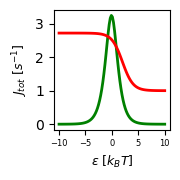

In [2]:
import matplotlib.pyplot as plt
plt.figure(figsize=(1.9,1.9))

# s3 = figure(title="Flux", x_range=(-10, 10), y_range=(0,5), tools="", toolbar_location=None, width=170, height=170)
plt.rcParams['font.sans-serif'] = ['Lucida Sans']
# plt.xlim(-10, 10)
# plt.ylim(0, 5)
plt.plot(epsilon_list, J_tot_list_cycle_r, color='green', label='Total Flux', linewidth=2,)
plt.plot(epsilon_list, [J_tot_list_cycle_w[i] for i in range(len(epsilon_list))], color='red', label='Total Flux', linewidth=2, )
# plt.plot(epsilon_list, J_limit_1_list, color='#92278f', linestyle='dashdot', label='Limit 1', linewidth=2)
# plt.plot(epsilon_list, J_limit_2_list, color='#f7941d', linestyle='dashdot', label='Limit 2', linewidth=2)
plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
plt.ylabel('$J_{tot} \ [s^{-1}]$', fontsize=9, fontdict={'family': 'sans-serif'})
plt.xticks([-10, -5, 0, 5, 10], fontsize=6)
# plt.yticks([i for i in range(0, 6)], fontsize=6)
ax = plt.gca()
for tick in ax.get_xticklabels():
    tick.set_fontname("Lucida Sans")
for tick in ax.get_yticklabels():
    tick.set_fontname("Lucida Sans")
# idx = np.argmin(np.abs(epsilon_list - epsilon_list[np.where(np.array(J_tot_list) == np.max(J_tot_list))[0][0]]))
# plt.scatter(epsilon_list[idx], J_tot_list[idx], color='red', s=50, label='Current Point')
# plt.legend()
plt.tight_layout()

<>:12: SyntaxWarning: invalid escape sequence '\e'
<>:13: SyntaxWarning: invalid escape sequence '\ '
<>:12: SyntaxWarning: invalid escape sequence '\e'
<>:13: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_776020/802484179.py:12: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
/tmp/ipykernel_776020/802484179.py:13: SyntaxWarning: invalid escape sequence '\ '
  plt.ylabel('$J_{tot} \ [s^{-1}]$', fontsize=9, fontdict={'family': 'sans-serif'})
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 

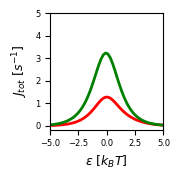

In [3]:
plt.figure(figsize=(1.9,1.9))

plt.plot(epsilon_list, [J_tot_list_cycle_r[i]/J_tot_list_cycle_w[i] for i in range(len(epsilon_list))], color='red', label='Selectivity', linewidth=2,)
plt.plot(epsilon_list, J_tot_list_cycle_r, color='green', label='Total Flux', linewidth=2,)

# plt.plot(epsilon_list, J_limit_1_list, color='#92278f', linestyle='dashdot', label='Limit 1', linewidth=2)
# plt.plot(epsilon_list, J_limit_2_list, color='#f7941d', linestyle='dashdot', label='Limit 2', linewidth=2)
# s3 = figure(title="Flux", x_range=(-5, 5), y_range=(0,5), tools="", toolbar_location=None, width=170, height=170)
plt.rcParams['font.sans-serif'] = ['Lucida Sans']
plt.xlim(-5, 5)
# plt.ylim(0, 5)
plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
plt.ylabel('$J_{tot} \ [s^{-1}]$', fontsize=9, fontdict={'family': 'sans-serif'})
plt.xticks([-5, -2.5, 0, 2.5, 5], fontsize=6)
plt.yticks([i for i in range(0, 6)], fontsize=6)
ax = plt.gca()
for tick in ax.get_xticklabels():
    tick.set_fontname("Lucida Sans")
for tick in ax.get_yticklabels():
    tick.set_fontname("Lucida Sans")
# idx = np.argmin(np.abs(epsilon_list - epsilon_list[np.where(np.array(J_tot_list) == np.max(J_tot_list))[0][0]]))
# plt.scatter(epsilon_list[idx], J_tot_list[idx], color='red', s=50, label='Current Point')
# plt.legend()
plt.tight_layout()

In [6]:
max_steady_state = np.max(J_tot_list_cycle_r)
def get_best_steady_state(**params):
    return max_steady_state

import numpy as np
import sys, os, time
from utilsGRF import BoundaryFinder as BF

#In all the examples, this will be fixed:

#Define the grid:
stp_ar=np.arange(1e-11, 1,0.005) #The mathematica files to check the results assume a grid spacing of 0.005. Change that if this is modified. 
pos_ar=np.arange(1e-11,5,0.025)

minp=1e-3
maxp=1e3


defaultsettings={'pars_limit':[minp,maxp],
           'row_ar':stp_ar,
          'col_ar':pos_ar,
          'seed':1,
         'mat':None,
         'mat_pars':None}


defaultargs={'niters':5, #for testing purposes only 5 iterations, or it will take very long
      'niters_conv':100,
      'niters_conv_points':1000,
      'niters_save':2,
      'prob_par':0.5,
      'prob_replace':0.5,
      'extr_uniform':[-1,1],
      'L_project':10,
      'plotting':True,
      'verbose':True,
       'dofirstmutate':True,
      'dopullcentroids':True,
      'dopulltangents':True} 

In [7]:
#code that runs the boundary exploration in the space given by the function myfN2
#set plotting:False in args dict when running for many iterations, so that no plots are shown
def rate_fn(*params):
    alpha_14, alpha_41, epsilon_1, epsilon_2 = params[0]
    epsilon_1 = np.log10(epsilon_1)
    epsilon_2 = np.log10(epsilon_2)
    right_cycles = [[2,3,4], [7,8,9], [2, 7, 8, 9, 4], [7, 2, 3, 4, 9], [7,2,3,8,9], [2,7,8,3,4], [2,3,8,9,7], [7,8,3,4,9]]
    wrong_cycles = [[2,1,0], [7,6,5], [2, 7, 6, 5, 0], [7, 2, 1, 0, 5], [7,2,1,6,5], [2,7,6,1,0], [2,1,6,5,7], [7,6,1,0,5]]
    return cycle_flux_fn(right_cycles, wrong_cycles, G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=get_best_steady_state, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                              alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                              alpha_21_w=alpha_21, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                              gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14, alpha_41=alpha_41)


outfolder="test"
if not os.path.isdir(outfolder):
    os.mkdir(outfolder)
name_save="namesave_g20000_sweep"
outfolder_final=outfolder
name='%s_last'%(name_save)


settings=defaultsettings.copy()
# constraints={1:{'target':0,'lt':1},3:{'target':2,'lt':1},5:{'target':4,'lt':1}} #the coefficients in the numerator are at most as large as the corresponding in the denominator

# settings['constraints']=constraints
settings['compute_x_y_f']=rate_fn
settings['npars']=4
# settings['mat'] = np.load(os.path.join(outfolder_final,'mat_namesave_g20000_sweep_6.npy'))
# settings['mat_pars'] = np.load(os.path.join(outfolder_final,'mat_pars_namesave_g20000_sweep_6.npy'))

#Initialise and get first 10 points

BE=BF.BoundaryExplorer(**settings)
BE.get_initial_points(10)

#Extend boundary

args=defaultargs.copy()
args["niters"]=20 #just for testing purposes
args['folder_save']=outfolder
args['name_save']=name_save
BE.extend_boundary(**args)


np.save(os.path.join(outfolder_final,'mat_'+name+'.npy'),BE.mat)
np.save(os.path.join(outfolder_final,'mat_pars_'+name+'.npy'),BE.mat_pars)

KeyboardInterrupt: 